# 01b · Tokenization, compared

**Preliminary notebook 01b** of the NER series in `techniques/ner/`. The main
class, `ner_pipeline.ipynb`, starts by cutting a clinical case report into
*tokens* twice: once with spaCy (words) and once with BERT's WordPiece
(sub-words). This notebook stops at that first step and looks at it closely:
what are the main ways of tokenizing text (`01a-tokenization-tokens.ipynb` is
the one-cell warm-up), how do they behave on clinical
English, and what does that mean for Named Entity Recognition?

```
                           tokenization approaches
        ┌────────────────────────┼──────────────────────────────┐
   word level               sub-word level                  byte level
   (rules)                  (learned vocabulary)            (no vocabulary)
        │          ┌─────────────┼──────────────┐                │
   spaCy /      BPE          WordPiece        Unigram LM        ByT5
   scispaCy   (RoBERTa,      (BERT, Biomed-   (ALBERT, XLM-R,
              GPT-2)          BERT)            via SentencePiece)
```

| § | Content |
|---|---|
| 1 | the same starting point as `ner_pipeline.ipynb`: MultiCaRe case, sentence splitting |
| 2 | **rule-based** word tokenization (spaCy vs scispaCy), and how its rules work |
| 3 | why sub-words: the out-of-vocabulary problem, measured on our corpus |
| 4 | the three sub-word algorithms — **BPE**, **WordPiece**, **Unigram** — each re-implemented in a few lines and checked against the real tokenizer; plus **bytes** |
| 5 | nine tokenizers side by side on the walkthrough sentence |
| 6 | clinical vocabulary: how each vocabulary splits medical words and abbreviations |
| 7 | corpus-level comparison tables (MultiCaRe sample) |
| 8 | the NER view: do token boundaries match gold entity boundaries? (MACCROBAT) |
| 9 | a controlled experiment: the three algorithms trained on the *same* corpus with the *same* vocabulary size |
| 10 | summary, and what it means for `ner_pipeline.ipynb` |

Only **tokenizers** are downloaded here (a few MB each), no model weights.
Cells marked **🧩 Challenge** are for you to solve.

## 0. Setup

In [1]:
import bisect
import json
import time
import warnings
from collections import Counter
from dataclasses import dataclass
from pathlib import Path
from typing import Callable

warnings.filterwarnings("ignore")  # quiet spaCy/transformers deprecation chatter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import spacy
import tokenizers
import transformers
from transformers import AutoTokenizer
from IPython.display import display

import ner_helpers

transformers.logging.set_verbosity_error()   # also hides "sequence longer than 512" warnings
transformers.utils.logging.disable_progress_bar()
pd.set_option("display.max_colwidth", 120)
pd.set_option("display.width", 200)

print("spaCy", spacy.__version__, "| transformers", transformers.__version__,
      "| tokenizers", tokenizers.__version__)

spaCy 3.7.5 | transformers 5.22.1 | tokenizers 0.23.3


In [2]:
# ---- configuration -------------------------------------------------------
CASES_CSV = "sample/cases.csv"
SPACY_MODEL = "en_core_sci_sm"      # same pipeline as ner_pipeline.ipynb

# The walkthrough sentence (same as ner_pipeline.ipynb).
CASE_ID = "PMC5137649_01"
SENTENCE_STARTS_WITH = "A 44-year-old woman presented"

SEQ_BUDGET = 512   # max input length of all the encoders compared here (BERT, RoBERTa, ALBERT, XLM-R)

# The tokenizers we compare: key -> (family, source, note)
TOKENIZERS = {
    "spaCy-en":     ("Rule-based", "spacy.blank('en')", "spaCy's default English rules"),
    "scispaCy":     ("Rule-based", "en_core_sci_sm", "rules tuned for biomedical text; used in ner_pipeline"),
    "BERT-uncased": ("WordPiece", "distilbert-base-uncased", "same vocabulary as d4data/biomedical-ner-all (ner_pipeline)"),
    "BERT-cased":   ("WordPiece", "bert-base-cased", "vocabulary also used by BioBERT and Bio_ClinicalBERT"),
    "BiomedBERT":   ("WordPiece", "microsoft/BiomedNLP-BiomedBERT-base-uncased-abstract-fulltext",
                     "a.k.a. PubMedBERT; vocabulary built from PubMed"),
    "RoBERTa":      ("BPE", "roberta-base", "byte-level BPE, same vocabulary as GPT-2"),
    "ALBERT":       ("Unigram", "albert-base-v2", "SentencePiece unigram, uncased"),
    "XLM-R":        ("Unigram", "xlm-roberta-base", "SentencePiece unigram, 100 languages"),
    "ByT5":         ("Bytes", "google/byt5-small", "no learned vocabulary: raw UTF-8 bytes"),
}

# One color per algorithm family, used in every chart (reference categorical palette, fixed order).
FAMILY_COLORS = {"WordPiece": "#2a78d6", "BPE": "#eb6834", "Unigram": "#1baf7a",
                 "Rule-based": "#eda100", "Bytes": "#e87ba4"}

plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.color": "#e4e4e0", "grid.linewidth": 0.8,
                     "axes.axisbelow": True, "font.size": 10})

## 1. The starting point: a case report, split into sentences

Exactly as in `ner_pipeline.ipynb`: we read the 50-article
[MultiCaRe](https://doi.org/10.5281/zenodo.10079369) sample, take one case,
and let scispaCy split it into sentences.

In [3]:
cases = pd.read_csv(CASES_CSV)
print(cases.shape, "→", cases.case_text.str.len().sum(), "characters in", len(cases), "case texts")
case_text = cases.set_index("case_id").loc[CASE_ID, "case_text"]

nlp = spacy.load(SPACY_MODEL)
doc = nlp(case_text)
sentences = [s.text for s in doc.sents]
sentence = next(s for s in sentences if s.startswith(SENTENCE_STARTS_WITH))
print(len(sentences), "sentences in", CASE_ID, "\n")
print(sentence)

(56, 5) → 185279 characters in 56 case texts


18 sentences in PMC5137649_01 

A 44-year-old woman presented with a 3-day history of right flank and lower quadrant abdominal pain associated with nausea and constipation.


Note the order of operations in spaCy: the **tokenizer runs first**, on the
whole text; sentences are found later (by the `parser`) as groups of tokens.
In `ner_pipeline.ipynb` we then hand each *sentence string* to the BERT
tokenizer, which tokenizes it again from scratch, with its own rules. The two
tokenizations only meet through **character offsets** — keep that in mind,
it is the theme of sections 5 and 8.

## 2. Rule-based word tokenization (spaCy)

spaCy's tokenizer has no special name in the literature: it is a
**rule-based, non-destructive tokenizer**, in the tradition of the
*Penn Treebank* tokenization conventions (split punctuation off words, split
clitics like `can't → ca n't`). Nothing is learned from data; the behavior is
entirely defined by a few rule sets that ship with the language/model:

| Rule set | What it does | Example |
|---|---|---|
| whitespace | first, split on spaces | `6cm x 9cm` → `6cm`, `x`, `9cm` |
| **special cases** (exceptions) | exact strings with a fixed tokenization, checked first | `Dr.` stays one token; `can't` → `ca`, `n't` |
| **prefixes** | regexes stripped repeatedly from the *start* | `(`, `"`, `$` |
| **suffixes** | regexes stripped repeatedly from the *end* | `)`, `.`, `%`, units like `cm` after a digit |
| **infixes** | regexes that split *inside* what is left | `-` between letters, `/` |
| token_match / url_match | patterns that must never be split | URLs, e-mails |

For each whitespace-separated chunk the algorithm loops: *is it a special
case? → strip a prefix → strip a suffix → ...*, then applies the infixes to
the remaining core. **Non-destructive** means every token remembers the
whitespace that followed it (`token.whitespace_`), so the original text can
always be rebuilt exactly.

`tokenizer.explain()` shows which rule produced each token:

In [4]:
nlp_en = spacy.blank("en")     # spaCy's default English tokenizer, nothing else
tricky = "She had EUS-FNA (6cm) and 12 mg/dl K+ on T2-weighted MRI, per Dr. Smith's note."

for name, pipeline_ in [("spaCy-en", nlp_en), ("scispaCy", nlp)]:
    print(f"── {name}")
    display(pd.DataFrame(pipeline_.tokenizer.explain(tricky), columns=["rule", "token"]).T)

── spaCy-en


,0,1,2,3,4,5,6,7,8,9,...,17,18,19,20,21,22,23,24,25,26
rule,TOKEN,TOKEN,TOKEN,INFIX,TOKEN,PREFIX,TOKEN,SUFFIX,SUFFIX,TOKEN,...,INFIX,TOKEN,TOKEN,SUFFIX,TOKEN,SPECIAL-1,TOKEN,SUFFIX,TOKEN,SUFFIX
token,She,had,EUS,-,FNA,(,6,cm,),and,...,-,weighted,MRI,",",per,Dr.,Smith,'s,note,.


── scispaCy


,0,1,2,3,4,5,6,7,8,9,...,11,12,13,14,15,16,17,18,19,20
rule,TOKEN,TOKEN,TOKEN,PREFIX,TOKEN,SUFFIX,SUFFIX,TOKEN,TOKEN,TOKEN,...,TOKEN,TOKEN,TOKEN,SUFFIX,TOKEN,SPECIAL-1,TOKEN,SUFFIX,TOKEN,SUFFIX
token,She,had,EUS-FNA,(,6,cm,),and,12,mg/dl,...,on,T2-weighted,MRI,",",per,Dr.,Smith,'s,note,.


`scispaCy` was trained with its own tokenizer rules (written by scispaCy's
`combined_rule_tokenizer` and **saved inside the model**): most notably it
does **not** split hyphens and slashes between letters, so `EUS-FNA`,
`T2-weighted` and `mg/dl` stay whole. Both share the same special cases
(`Dr.`, `'s`).

A few more strings from clinical writing:

In [5]:
CLINICAL_STRINGS = ["A 44-year-old woman", "6cm x 9cm", "EUS-FNA", "body/tail", "(Fig 1).",
                    "1/128 at 4 C", "IL-6", "12 mg/dl", "K+ 2.9 mmol/L", "p.o. b.i.d.",
                    "T2-weighted", "≥38.5°C", "HbA1c 7.2%", "COVID-19", "can't"]

def show(tokens):
    return " │ ".join(tokens)

pd.DataFrame([{"text": s,
               "spaCy-en": show(t.text for t in nlp_en.tokenizer(s)),
               "scispaCy": show(t.text for t in nlp.tokenizer(s))} for s in CLINICAL_STRINGS])

,text,spaCy-en,scispaCy
0,A 44-year-old woman,A │ 44 │ - │ year │ - │ old │ woman,A │ 44-year-old │ woman
1,6cm x 9cm,6 │ cm │ x │ 9 │ cm,6 │ cm │ x │ 9 │ cm
2,EUS-FNA,EUS │ - │ FNA,EUS-FNA
3,body/tail,body │ / │ tail,body/tail
4,(Fig 1).,( │ Fig │ 1 │ ) │ .,( │ Fig │ 1 │ ) │ .
5,1/128 at 4 C,1/128 │ at │ 4 │ C,1/128 │ at │ 4 │ C
6,IL-6,IL-6,IL-6
7,12 mg/dl,12 │ mg │ / │ dl,12 │ mg/dl
8,K+ 2.9 mmol/L,K+ │ 2.9 │ mmol │ / │ L,K+ │ 2.9 │ mmol/L
9,p.o. b.i.d.,p.o │ . │ b.i.d │ .,p.o │ . │ b.i.d │ .


In [6]:
# Non-destructive: tokens + their trailing whitespace rebuild the text exactly.
t = nlp.tokenizer(sentence)
print([(tok.text, tok.whitespace_) for tok in t][:8])
print("rebuilt == original:", "".join(tok.text_with_ws for tok in t) == sentence)
print("special cases:", len(nlp_en.tokenizer.rules), "(spaCy-en) vs", len(nlp.tokenizer.rules), "(scispaCy)")

[('A', ' '), ('44-year-old', ' '), ('woman', ' '), ('presented', ' '), ('with', ' '), ('a', ' '), ('3-day', ' '), ('history', ' ')]
rebuilt == original: True
special cases: 1347 (spaCy-en) vs 1367 (scispaCy)


**Strengths:** fast, transparent, linguistically meaningful units (words,
numbers, punctuation), lossless. **Weakness:** a word tokenizer only *cuts*;
a model that consumes its tokens needs a **vocabulary of words**, and that
is where the trouble starts.

## 3. Why sub-words? The out-of-vocabulary problem

Suppose a model knew every word of half of our case reports. How much of the
other half would be unknown to it?

In [7]:
def words_of(text):
    # lower-cased scispaCy tokens, without whitespace tokens
    return [t.lower_ for t in nlp.tokenizer(text) if not t.is_space]

train_words = Counter(w for text in cases.case_text[::2] for w in words_of(text))
test_words = [w for text in cases.case_text[1::2] for w in words_of(text)]

rows = []
for min_count in [1, 2, 5]:
    vocab = {w for w, c in train_words.items() if c >= min_count}
    oov = [w for w in test_words if w not in vocab]
    rows.append({"vocabulary = train words seen ≥ k times": min_count, "vocabulary size": len(vocab),
                 "OOV tokens (%)": round(100 * len(oov) / len(test_words), 1),
                 "OOV word types (%)": round(100 * len(set(oov)) / len(set(test_words)), 1)})
display(pd.DataFrame(rows))

oov = Counter(w for w in test_words if w not in train_words)
print("frequent unknown words in the test half:", [w for w, _ in oov.most_common(25)])

,vocabulary = train words seen ≥ k times,vocabulary size,OOV tokens (%),OOV word types (%)
0,1,3126,21.2,61.6
1,2,1411,27.8,75.1
2,5,478,37.5,89.3


frequent unknown words in the test half: ['theranos', 'gibbons', 'holmes', 'u/l', 'r', 'stoma', 'secondary', '5/5', 'jejunal', 'isolates', 'carreyrou', 'mumol/l', 'shunt', 'deficits', '4/5', 'hadv-14', 'gj', 'egd', 'requiring', 'immediately', 'considering', 'specimen', 'markers', 'sequencing', 'added']


Even with every training word kept, a large share of test words was never
seen — and they are exactly the informative ones (drug names, rare diseases,
measurements). A word-level model maps all of them to one `[UNK]` vector.
Growing the vocabulary does not solve this (it explodes, and there is always
a new word).

**Sub-word tokenization** keeps a *fixed* vocabulary (≈30–250k entries) of
frequent words **and** word fragments, so any word can be written as a
sequence of known pieces: frequent words stay whole, rare ones are spelled
out with fragments, and in the limit with single characters or bytes. All
three algorithms below learn such a vocabulary from a corpus; they differ in
**how the vocabulary is built** and **how a word is segmented** with it.

## 4. The three sub-word algorithms (and bytes)

### 4.1 BPE — Byte-Pair Encoding

*Sennrich et al., 2016* (adapted from a 1994 compression algorithm).
**Training** starts from single characters and repeatedly **merges the most
frequent adjacent pair** of symbols into a new symbol, recording each merge.
**Segmenting** a new word replays the merges in the order they were learned.
Used by GPT-2/3/4, RoBERTa, ModernBERT, Llama, ...

Here is the whole training loop, run on the word counts of our sample:

In [8]:
def bpe_train(word_freqs, n_merges):
    splits = {w: list(w) for w in word_freqs}       # every word starts as characters
    merges = []
    for _ in range(n_merges):
        pairs = Counter()                            # count adjacent symbol pairs
        for w, f in word_freqs.items():
            sym = splits[w]
            for a, b in zip(sym, sym[1:]):
                pairs[a, b] += f
        if not pairs:
            break
        (a, b), freq = pairs.most_common(1)[0]       # the most frequent pair ...
        merges.append((a, b, freq))
        for w in word_freqs:                         # ... becomes one symbol everywhere
            splits[w] = merge_pair(splits[w], a, b)
    return merges

def merge_pair(sym, a, b):
    out, i = [], 0
    while i < len(sym):
        if i < len(sym) - 1 and sym[i] == a and sym[i + 1] == b:
            out.append(a + b); i += 2
        else:
            out.append(sym[i]); i += 1
    return out

def bpe_segment(word, merges):
    sym = list(word)
    for a, b, _ in merges:                           # replay merges in learned order
        sym = merge_pair(sym, a, b)
    return sym

alpha_freqs = Counter(w for text in cases.case_text for w in words_of(text) if w.isalpha())
t0 = time.time()
merges = bpe_train(alpha_freqs, n_merges=300)
print(f"{len(alpha_freqs)} word types, 300 merges learned in {time.time() - t0:.1f}s")

pd.DataFrame([{"step": i + 1, "merge": f"{a} + {b} → {a + b}", "pair frequency": f}
              for i, (a, b, f) in enumerate(merges[:15])]).set_index("step").T

4689 word types, 300 merges learned in 1.9s


step,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15
merge,t + h → th,i + n → in,e + r → er,a + n → an,a + t → at,o + n → on,e + d → ed,e + n → en,a + l → al,th + e → the,r + e → re,a + s → as,o + r → or,an + d → and,en + t → ent
pair frequency,3138,2626,2303,2157,2091,2054,2002,1964,1723,1692,1654,1474,1292,1088,1086


In [9]:
# The same words, segmented with the first k merges only: the vocabulary "grows" pieces.
words_demo = ["hypokalemia", "constipation", "pancreatitis", "cholecystectomy", "abdominal"]
pd.DataFrame({f"{k} merges": [" ".join(bpe_segment(w, merges[:k])) for w in words_demo]
              for k in [0, 50, 150, 300]}, index=words_demo)

,0 merges,50 merges,150 merges,300 merges
hypokalemia,h y p o k a l e m i a,h y p o k al e m i a,hy po k al e m ia,hy po k al em ia
constipation,c o n s t i p a t i o n,c on st i p ation,con st i p ation,con st i p ation
pancreatitis,p a n c r e a t i t i s,p an c re ati t is,p an c re ati t is,p an cre ati t is
cholecystectomy,c h o l e c y s t e c t o m y,c h o le c y st e c to m y,ch o le c y st e c to m y,ch o le cy st e c tom y
abdominal,a b d o m i n a l,a b d om in al,ab d om in al,abdom inal


> Simplifications: the original algorithm adds an end-of-word marker
> (`</w>`) so that word-final pieces differ from word-internal ones, and real
> tokenizers learn tens of thousands of merges on gigabytes of text.

**Byte-level BPE** (GPT-2, RoBERTa) runs the same algorithm over the
**UTF-8 bytes** of the text instead of characters: the base alphabet is
then just 256 symbols, so *nothing* is ever unknown. To make bytes printable,
each one is mapped to a visible character — the space byte becomes `Ġ`, and
a two-byte character like `é` shows up as two symbols (`Ã©`):

In [10]:
roberta = AutoTokenizer.from_pretrained("roberta-base")
s = "Naïve café patient, T ≥38.5°C"
pieces = roberta.tokenize(s)
pd.DataFrame({"piece": pieces,
              "decodes to": [repr(roberta.convert_tokens_to_string([p])) for p in pieces]}).T

,0,1,2,3,4,5,6,7,8,9,10,11
piece,Na,Ã¯ve,ĠcafÃ©,Ġpatient,",",ĠT,Ġâī¥,38,.,5,Â°,C
decodes to,'Na','ïve',' café',' patient',"','",' T',' ≥','38','.','5','°','C'


The space is **part of the token** (`Ġwoman` = " woman"), so a word at the
start of a sentence (`A`, no space before) and the same word inside it
(`ĠA`) are *different* tokens. Pieces whose bytes do not form a complete
character decode to `�` on their own.

### 4.2 WordPiece

*Schuster & Nakajima, 2012*; made famous by BERT (Devlin et al., 2019).
Two differences from BPE:

* **Training** merges the pair that most increases the likelihood of the
  corpus, i.e. the pair with the highest `freq(ab) / (freq(a) · freq(b))`
  rather than the highest `freq(ab)`: it prefers pairs whose parts are rarely
  seen apart. (Google never released its trainer; Hugging Face's
  `WordPieceTrainer` actually runs BPE merges — see section 9.)
* **Segmenting** ignores the merge history: it takes the **longest prefix
  found in the vocabulary**, then the longest continuation piece (marked
  `##`), and so on. If at some point no piece fits, the **whole word**
  becomes `[UNK]`.

Before that, BERT's tokenizer *normalizes* (lower-cases and strips accents in
the uncased models) and *pre-tokenizes* on whitespace **and every punctuation
character**. Greedy longest-match, from scratch, against BERT's real vocabulary:

In [11]:
bert = AutoTokenizer.from_pretrained("distilbert-base-uncased")
bert_vocab = bert.get_vocab()                       # piece -> id, 30,522 entries

def wordpiece_segment(word, vocab, unk="[UNK]"):
    pieces, start = [], 0
    while start < len(word):
        end = len(word)
        while end > start:                          # longest piece that is in the vocabulary
            piece = word[start:end] if start == 0 else "##" + word[start:end]
            if piece in vocab:
                break
            end -= 1
        else:
            return [unk]                            # no piece fits: the WHOLE word is unknown
        pieces.append(piece)
        start = end
    return pieces

test = ["constipation", "hypokalemia", "dyspnea", "echocardiography", "pancreatic",
        "methylprednisolone", "lymphadenopathy", "woman"]
pd.DataFrame([{"word": w, "ours": " ".join(wordpiece_segment(w, bert_vocab)),
               "Hugging Face": " ".join(bert.tokenize(w)),
               "same": wordpiece_segment(w, bert_vocab) == bert.tokenize(w)} for w in test])

,word,ours,Hugging Face,same
0,constipation,con ##sti ##pati ##on,con ##sti ##pati ##on,True
1,hypokalemia,h ##yp ##oka ##lem ##ia,h ##yp ##oka ##lem ##ia,True
2,dyspnea,d ##ys ##p ##nea,d ##ys ##p ##nea,True
3,echocardiography,echo ##card ##iography,echo ##card ##iography,True
4,pancreatic,pan ##cre ##atic,pan ##cre ##atic,True
5,methylprednisolone,methyl ##pre ##d ##nis ##olo ##ne,methyl ##pre ##d ##nis ##olo ##ne,True
6,lymphadenopathy,l ##ym ##pha ##den ##opa ##thy,l ##ym ##pha ##den ##opa ##thy,True
7,woman,woman,woman,True


### 4.3 Unigram language model (SentencePiece)

*Kudo, 2018*; usually trained with the **SentencePiece** library (Kudo &
Richardson, 2018) and used by ALBERT, T5, XLM-R, mBART, ... Unigram works the
other way round:

* **Training** starts from a *huge* candidate vocabulary and repeatedly
  **removes** the pieces whose loss least hurts the corpus likelihood (fitted
  with EM), until the target size is reached. Each piece keeps a probability.
* **Segmenting** picks, among *all* possible segmentations of a word, the one
  with the **highest total probability** (sum of log-probabilities), found
  with the Viterbi algorithm. Several segmentations can be scored — sampling
  among them (*subword regularization*) is a training trick of this family.

SentencePiece also treats the text as a raw character stream: the space is
replaced by `▁` and kept *inside* the pieces (`▁woman`), which makes the
tokenization reversible without language-specific pre-tokenization.

Viterbi, from scratch, with ALBERT's own piece scores:

In [12]:
albert = AutoTokenizer.from_pretrained("albert-base-v2")
albert_logp = dict(json.loads(albert.backend_tokenizer.to_str())["model"]["vocab"])  # piece -> log p
print(len(albert_logp), "pieces; e.g.", {p: round(albert_logp[p], 2) for p in ["▁the", "▁pain", "emia", "▁hypo"]})

def unigram_segment(word, logp):
    n = len(word)
    best = [0.0] + [-np.inf] * n        # best[i] = best score of word[:i]
    back = [0] * (n + 1)                # where the last piece of that best segmentation starts
    for end in range(1, n + 1):
        for start in range(end):
            piece = word[start:end]
            if piece in logp and best[start] + logp[piece] > best[end]:
                best[end], back[end] = best[start] + logp[piece], start
    pieces, end = [], n
    while end > 0:
        pieces.append(word[back[end]:end]); end = back[end]
    return pieces[::-1], best[n]

def score(pieces, logp):
    return sum(logp.get(p, -np.inf) for p in pieces)

rows = []
for w in ["hypokalemia", "constipation", "dyspnea", "echocardiography", "methylprednisolone"]:
    ours, s = unigram_segment("▁" + w, albert_logp)
    rows.append({"word": w, "ours (Viterbi)": " ".join(ours), "log p": round(s, 1),
                 "Hugging Face": " ".join(albert.tokenize(w)), "same": ours == albert.tokenize(w)})
pd.DataFrame(rows)

30000 pieces; e.g. {'▁the': -3.07, '▁pain': -9.45, 'emia': -11.78, '▁hypo': -11.46}


,word,ours (Viterbi),log p,Hugging Face,same
0,hypokalemia,▁hypo kal emia,-34.4,▁hypo kal emia,True
1,constipation,▁cons tip ation,-32.5,▁cons tip ation,True
2,dyspnea,▁dys p nea,-31.9,▁dys p nea,True
3,echocardiography,▁echo cardi ography,-35.5,▁echo cardi ography,True
4,methylprednisolone,▁ methyl pre d ni sol one,-59.5,▁ methyl pre d ni sol one,True


In [13]:
# Viterbi chose the best of many candidates. A few others, scored with the same table:
candidates = [unigram_segment("▁hypokalemia", albert_logp)[0],
              ["▁hypo", "ka", "le", "mia"],                     # BiomedBERT's split, in ▁ notation
              ["▁h", "yp", "oka", "lem", "ia"],                  # BERT-uncased's split
              list("▁hypokalemia")]                              # characters
pd.DataFrame([{"segmentation": " ".join(c), "pieces": len(c), "log p": round(score(c, albert_logp), 1)}
              for c in candidates])

,segmentation,pieces,log p
0,▁hypo kal emia,3,-34.4
1,▁hypo ka le mia,4,-40.2
2,▁h yp oka lem ia,5,-52.2
3,▁ h y p o k a l e m i a,12,-80.9


### 4.4 Bytes: no vocabulary at all

At the extreme, **ByT5** (Xue et al., 2022) skips vocabulary learning: the
tokens are the UTF-8 bytes of the text (256 ids, +3 special). Nothing is
unknown and nothing is learned — but sequences get several times longer, and
the model must learn spelling from scratch.

In [14]:
byt5 = AutoTokenizer.from_pretrained("google/byt5-small")
s = "café 6cm"
ids = byt5(s)["input_ids"]
print(ids, "← last id is </s>")
print("ids == UTF-8 bytes + 3 :", ids[:-1] == [b + 3 for b in s.encode("utf-8")])
print(len(s), "characters →", len(s.encode("utf-8")), "bytes (é takes two)")

[102, 100, 105, 198, 172, 35, 57, 102, 112, 1] ← last id is </s>
ids == UTF-8 bytes + 3 : True
8 characters → 9 bytes (é takes two)


## 5. Nine tokenizers, side by side

To compare them we wrap every tokenizer behind the same tiny interface:
`tokenize(text) → [(piece, char_start, char_end), ...]` (no special tokens).
The character offsets are what lets us line everything up — the Hugging Face
"fast" tokenizers return them (`return_offsets_mapping=True`), spaCy tokens
carry them (`token.idx`), and for bytes we compute them.

**Reference unit.** "Word" means a **scispaCy token** throughout, since that
is the word tokenization `ner_pipeline.ipynb` uses.

In [15]:
@dataclass
class Tok:
    key: str
    family: str
    source: str
    note: str
    tokenize: Callable[[str], list]      # text -> [(piece, start, end), ...], no special tokens
    roundtrip: Callable[[str], str]      # text -> what you get back after encode + decode
    vocab_size: int | None               # None = open vocabulary (rule-based)
    n_special: int                       # special tokens added to one sequence ([CLS], [SEP], </s>, ...)
    unk: str | None


def spacy_tok(key, family, source, note, nlp_obj):
    def tokenize(text):
        return [(t.text, t.idx, t.idx + len(t.text)) for t in nlp_obj.tokenizer(text) if not t.is_space]
    def roundtrip(text):
        return "".join(t.text_with_ws for t in nlp_obj.tokenizer(text))
    return Tok(key, family, source, note, tokenize, roundtrip, None, 0, None)


def hf_tok(key, family, source, note):
    tk = AutoTokenizer.from_pretrained(source)
    def tokenize(text):
        enc = tk(text, add_special_tokens=False, return_offsets_mapping=True)
        return [(p, s, e) for p, (s, e) in zip(tk.convert_ids_to_tokens(enc["input_ids"]), enc["offset_mapping"])]
    def roundtrip(text):
        return tk.decode(tk(text, add_special_tokens=False)["input_ids"])
    return Tok(key, family, source, note, tokenize, roundtrip, len(tk), tk.num_special_tokens_to_add(), tk.unk_token)


def byte_piece(b):
    return "␣" if b == 32 else chr(b) if 32 < b < 127 else f"<{b:02X}>"

def bytes_tok(key, family, source, note):
    def tokenize(text):   # same ids as the ByT5 tokenizer (checked in 4.4), with offsets
        return [(byte_piece(b), i, i + 1) for i, ch in enumerate(text) for b in ch.encode("utf-8")]
    def roundtrip(text):
        return bytes(b for ch in text for b in ch.encode("utf-8")).decode("utf-8")
    return Tok(key, family, source, note, tokenize, roundtrip, 256, 1, None)


TOKS = {}
for key, (family, source, note) in TOKENIZERS.items():
    if key == "spaCy-en":
        TOKS[key] = spacy_tok(key, family, source, note, nlp_en)
    elif key == "scispaCy":
        TOKS[key] = spacy_tok(key, family, source, note, nlp)
    elif family == "Bytes":
        TOKS[key] = bytes_tok(key, family, source, note)
    else:
        TOKS[key] = hf_tok(key, family, source, note)

pd.DataFrame([{"tokenizer": t.key, "family": t.family, "source": t.source,
               "vocabulary": "open (rules)" if t.vocab_size is None else f"{t.vocab_size:,}",
               "note": t.note} for t in TOKS.values()]).set_index("tokenizer")

,family,source,vocabulary,note
tokenizer,,,,
spaCy-en,Rule-based,spacy.blank('en'),open (rules),spaCy's default English rules
scispaCy,Rule-based,en_core_sci_sm,open (rules),rules tuned for biomedical text; used in ner_pipeline
BERT-uncased,WordPiece,distilbert-base-uncased,"30,522",same vocabulary as d4data/biomedical-ner-all (ner_pipeline)
BERT-cased,WordPiece,bert-base-cased,"28,996",vocabulary also used by BioBERT and Bio_ClinicalBERT
BiomedBERT,WordPiece,microsoft/BiomedNLP-BiomedBERT-base-uncased-abstract-fulltext,"30,522",a.k.a. PubMedBERT; vocabulary built from PubMed
RoBERTa,BPE,roberta-base,"50,265","byte-level BPE, same vocabulary as GPT-2"
ALBERT,Unigram,albert-base-v2,"30,000","SentencePiece unigram, uncased"
XLM-R,Unigram,xlm-roberta-base,"250,002","SentencePiece unigram, 100 languages"
ByT5,Bytes,google/byt5-small,256,no learned vocabulary: raw UTF-8 bytes


In [16]:
# Is the tokenizer of the fine-tuned NER model (ner_pipeline) really BERT-uncased's?
ft = AutoTokenizer.from_pretrained("d4data/biomedical-ner-all")
print("d4data/biomedical-ner-all vocabulary == distilbert-base-uncased vocabulary:",
      ft.get_vocab() == bert.get_vocab())

d4data/biomedical-ner-all vocabulary == distilbert-base-uncased vocabulary: True


To line two tokenizations up we only need character offsets: a token
*overlaps* a word if their character ranges intersect. A token that overlaps
**two or more words** crosses a word boundary (we will mark it with `*`).

In [17]:
def align(words, toks):
    # words: [(start, end)] sorted; toks: [(piece, start, end)]
    # returns word2toks (token indices per word) and tok2words (word indices per token)
    starts = [s for s, _ in words]
    ends = [e for _, e in words]
    tok2words = []
    for _, s, e in toks:
        if e <= s:                                   # zero-width token
            tok2words.append([]); continue
        first = bisect.bisect_right(ends, s)         # first word ending after the token starts
        last = bisect.bisect_left(starts, e) - 1     # last word starting before the token ends
        tok2words.append(list(range(first, last + 1)))
    word2toks = [[] for _ in words]
    for ti, ws in enumerate(tok2words):
        for w in ws:
            word2toks[w].append(ti)
    return word2toks, tok2words


def reference_words(text):
    return [(s, e) for _, s, e in TOKS["scispaCy"].tokenize(text)]


def side_by_side(text, keys=None):
    words = reference_words(text)
    table = {}
    for key in keys or TOKS:
        toks = TOKS[key].tokenize(text)
        w2t, t2w = align(words, toks)
        col = [" ".join(toks[i][0] + ("*" if len(t2w[i]) > 1 else "") for i in idxs) for idxs in w2t]
        table[key] = col + [len(toks)]
    return pd.DataFrame(table, index=[text[s:e] for s, e in words] + ["── tokens"])

print(sentence)
side_by_side(sentence)

A 44-year-old woman presented with a 3-day history of right flank and lower quadrant abdominal pain associated with nausea and constipation.


,spaCy-en,scispaCy,BERT-uncased,BERT-cased,BiomedBERT,RoBERTa,ALBERT,XLM-R,ByT5
A,A,A,a,A,a,A,▁a,▁A,A
44-year-old,44 - year - old,44-year-old,44 - year - old,44 - year - old,44 - year - old,Ġ44 - year - old,▁44 - year - old,▁44 - year - old,4 4 - y e a r - o l d
woman,woman,woman,woman,woman,woman,Ġwoman,▁woman,▁woman,w o m a n
presented,presented,presented,presented,presented,presented,Ġpresented,▁presented,▁presente d,p r e s e n t e d
with,with,with,with,with,with,Ġwith,▁with,▁with,w i t h
a,a,a,a,a,a,Ġa,▁a,▁a,a
3-day,3 - day,3-day,3 - day,3 - day,3 - day,Ġ3 - day,▁3 - day,▁3- day,3 - d a y
history,history,history,history,history,history,Ġhistory,▁history,▁history,h i s t o r y
of,of,of,of,of,of,Ġof,▁of,▁of,o f
right,right,right,right,right,right,Ġright,▁right,▁right,r i g h t


Things to look for:

* **Rule-based vs sub-word.** scispaCy keeps `44-year-old` as one token;
  every other tokenizer splits it at the hyphens — BERT's pre-tokenizer
  splits on *every* punctuation character before WordPiece even starts.
* **Case.** The uncased tokenizers (BERT-uncased, BiomedBERT, ALBERT) see
  `a`, not `A`.
* **Spaces inside tokens.** RoBERTa's `Ġ` and SentencePiece's `▁` carry the
  preceding space, so the first word of a sentence is a different token than
  the same word mid-sentence (`A` vs `ĠA`).
* **Domain vocabulary.** BiomedBERT has `constipation` as a single piece;
  the general BERT vocabulary needs four.
* **Crossing tokens** (`*`): none here, but byte-level BPE and SentencePiece
  do produce them elsewhere (section 7).
* **Bytes** are honest but long: 140 positions for a sentence that costs
  22 words or ~30 sub-word tokens.

## 6. Clinical vocabulary

How each vocabulary handles medical words (rule-based tokenizers are left
out: they never split a plain word). First the number of pieces, then the
pieces themselves:

In [18]:
CLINICAL_WORDS = ["fever", "pain", "nausea", "constipation", "dyspnea", "hypokalemia", "tachycardia",
                  "pancreatitis", "pneumothorax", "adenocarcinoma", "lymphadenopathy",
                  "cholecystectomy", "echocardiography", "thrombocytopenia",
                  "immunohistochemistry", "methylprednisolone", "ceftriaxone", "hepatosplenomegaly"]
SUBWORD_KEYS = [k for k, t in TOKS.items() if t.family not in ("Rule-based",)]

pieces_of = {k: {w: [p for p, _, _ in TOKS[k].tokenize(w)] for w in CLINICAL_WORDS} for k in SUBWORD_KEYS}
counts = pd.DataFrame({k: {w: len(p) for w, p in d.items()} for k, d in pieces_of.items()})
counts.loc["── mean"] = counts.mean().round(2)
counts.style.background_gradient(cmap="Blues", axis=None, subset=(CLINICAL_WORDS, SUBWORD_KEYS[:-1])).format(precision=2)

,BERT-uncased,BERT-cased,BiomedBERT,RoBERTa,ALBERT,XLM-R,ByT5
fever,1.00,1.00,1.00,2.00,1.00,2.00,5.00
pain,1.00,1.00,1.00,1.00,1.00,1.00,4.00
nausea,1.00,1.00,1.00,3.00,1.00,3.00,6.00
constipation,4.00,4.00,1.00,2.00,3.00,4.00,12.00
dyspnea,4.00,4.00,1.00,4.00,3.00,3.00,7.00
hypokalemia,5.00,5.00,4.00,4.00,3.00,3.00,11.00
tachycardia,4.00,4.00,1.00,4.00,4.00,4.00,11.00
pancreatitis,4.00,4.00,1.00,4.00,4.00,3.00,12.00
pneumothorax,6.00,5.00,1.00,5.00,4.00,4.00,12.00
adenocarcinoma,5.00,5.00,1.00,5.00,5.00,5.00,14.00


In [19]:
pd.DataFrame({k: {w: " ".join(p) for w, p in d.items()} for k, d in pieces_of.items() if k != "ByT5"})

,BERT-uncased,BERT-cased,BiomedBERT,RoBERTa,ALBERT,XLM-R
fever,fever,fever,fever,f ever,▁fever,▁fe ver
pain,pain,pain,pain,pain,▁pain,▁pain
nausea,nausea,nausea,nausea,n ause a,▁nausea,▁na use a
constipation,con ##sti ##pati ##on,con ##st ##ip ##ation,constipation,const ipation,▁cons tip ation,▁con s tip ation
dyspnea,d ##ys ##p ##nea,d ##ys ##p ##nea,dyspnea,d ys p nea,▁dys p nea,▁dys pne a
hypokalemia,h ##yp ##oka ##lem ##ia,h ##y ##po ##kal ##emia,hypo ##ka ##le ##mia,hyp ok al emia,▁hypo kal emia,▁hypo kal emia
tachycardia,ta ##chy ##card ##ia,ta ##chy ##card ##ia,tachycardia,t achy card ia,▁ta chy cardi a,▁ta chy car dia
pancreatitis,pan ##cre ##ati ##tis,pan ##cre ##ati ##tis,pancreatitis,p anc reat itis,▁pan crea t itis,▁pan creati tis
pneumothorax,p ##ne ##um ##otho ##ra ##x,p ##ne ##um ##oth ##orax,pneumothorax,p neum oth or ax,▁p neu mo thorax,▁pneu mot hora x
adenocarcinoma,aden ##oca ##rc ##ino ##ma,ad ##eno ##car ##cin ##oma,adenocarcinoma,aden oc arc in oma,▁aden o car cino ma,▁a den oca rci noma


Two lessons:

1. **The vocabulary matters more than the algorithm.** BERT-uncased and
   BiomedBERT use the *same* algorithm, vocabulary size and normalization;
   only the corpus the vocabulary was built from differs (Wikipedia + books
   vs PubMed), and BiomedBERT keeps most clinical words whole.
2. **Pieces are not morphemes.** `hypo + kal + emia` (ALBERT) is close to
   the real morphology (*hypo-* + *kal(ium)* + *-emia*); `h + ##yp + ##oka +
   ##lem + ##ia` (BERT-uncased) is not. A frequency-driven vocabulary only
   finds morphemes when they are frequent in its training corpus.

Abbreviations and notation, where **case** and **punctuation** carry meaning:

In [20]:
NOTATION = ["CT", "US", "us", "IL-6", "HbA1c", "SARS-CoV-2", "EUS-FNA", "mmol/L", "≥38.5°C", "Naïve"]
pd.DataFrame({k: {s: " ".join(p for p, _, _ in TOKS[k].tokenize(s)) for s in NOTATION}
              for k in TOKS if k != "ByT5"})

,spaCy-en,scispaCy,BERT-uncased,BERT-cased,BiomedBERT,RoBERTa,ALBERT,XLM-R
CT,CT,CT,ct,CT,ct,CT,▁ ct,▁CT
US,US,US,us,US,us,US,▁us,▁US
us,us,us,us,us,us,us,▁us,▁us
IL-6,IL-6,IL-6,il - 6,IL - 6,il - 6,IL - 6,▁il - 6,▁IL -6
HbA1c,HbA1c,HbA1c,h ##ba ##1 ##c,H ##b ##A ##1 ##c,hba1c,H b A 1 c,▁h ba 1 c,▁H b A 1 c
SARS-CoV-2,SARS - CoV-2,SARS-CoV-2,sar ##s - co ##v - 2,SA ##RS - Co ##V - 2,sars - cov - 2,S ARS - Co V - 2,▁sar s - c ov - 2,▁S ARS - Co V -2
EUS-FNA,EUS - FNA,EUS-FNA,eu ##s - f ##na,EU ##S - F ##NA,eus - fna,E US - F NA,▁ eus - f na,▁ EUS - F NA
mmol/L,mmol / L,mmol/L,mm ##ol / l,mm ##ol / L,mmol / l,mm ol / L,▁mm ol / l,▁mm ol / L
≥38.5°C,≥38.5 ° C,≥38.5 ° C,≥ ##38 . 5 ##° ##c,≥ ##38 . 5 ##° ##C,≥3 ##8 . 5°c,âī ¥ 38 . 5 Â° C,▁ <unk> 38 . 5 <unk> c,▁ ≥ 38 . 5° C
Naïve,Naïve,Naïve,naive,Na ##ï ##ve,naive,Na Ã¯ve,▁naive,▁Na ï ve


Uncased tokenizers cannot tell **US** (ultrasound) from **us**, and they strip
accents (`naive`). All the sub-word tokenizers break `IL-6` and `SARS-CoV-2`
at the hyphens; the rule-based ones keep `IL-6` whole, and spaCy-en splits
`SARS-CoV-2` only once — its infix rule splits a hyphen between two
*letters* (`S-C`), not between a letter and a digit (`V-2`). ALBERT has no
piece for `≥` or `°` at all: they become `<unk>`.

## 7. The whole sample, measured

Now every tokenizer on all 56 case texts of the sample (≈185k characters).
For each one:

| Column | Meaning |
|---|---|
| tokens / word | tokens produced per scispaCy word (*fertility*); 1.0 = one token per word |
| chars / token | average characters covered by a token (higher = more compact) |
| words kept whole (%) | words represented by exactly one token with the same boundaries |
| tokens crossing a word boundary (%) | tokens overlapping two or more scispaCy words |
| [UNK] tokens | pieces mapped to the unknown token |
| tokens / case (mean, max) | sequence length per case report, *including* special tokens |
| cases > 512 (%) | cases that do not fit in one encoder input and must be truncated or chunked |
| exact round-trip (%) | cases where `decode(encode(text)) == text` |
| time (s) | tokenizing the 56 texts on this machine (rough indication only) |

In [21]:
def corpus_stats(tok, texts):
    n_words = n_tokens = n_chars = whole = crossing = unk = exact = 0
    per_case, unk_examples = [], Counter()
    pieces_per_word = Counter()
    t0 = time.perf_counter()
    tokenized = [tok.tokenize(t) for t in texts]
    elapsed = time.perf_counter() - t0
    for text, toks in zip(texts, tokenized):
        words = reference_words(text)
        w2t, t2w = align(words, toks)
        n_words += len(words); n_tokens += len(toks); n_chars += len(text)
        per_case.append(len(toks) + tok.n_special)
        for (ws, we), idxs in zip(words, w2t):
            pieces_per_word[min(len(idxs), 4)] += 1
            if len(idxs) == 1 and toks[idxs[0]][1:] == (ws, we):
                whole += 1
        crossing += sum(len(ws) > 1 for ws in t2w)
        for p, s, e in toks:
            if tok.unk is not None and p == tok.unk:
                unk += 1; unk_examples[text[s:e]] += 1
        exact += tok.roundtrip(text) == text
    per_case = np.array(per_case)
    return {
        "family": tok.family,
        "tokens / word": n_tokens / n_words,
        "chars / token": n_chars / n_tokens,
        "words kept whole (%)": 100 * whole / n_words,
        "tokens crossing a word boundary (%)": 100 * crossing / n_tokens,
        "[UNK] tokens": unk,
        "tokens / case (mean)": per_case.mean(),
        "tokens / case (max)": per_case.max(),
        "cases > 512 (%)": 100 * (per_case > SEQ_BUDGET).mean(),
        "exact round-trip (%)": 100 * exact / len(texts),
        "time (s)": elapsed,
        "_pieces_per_word": pieces_per_word,
        "_unk_examples": unk_examples,
    }

texts = cases.case_text.tolist()
stats = {key: corpus_stats(tok, texts) for key, tok in TOKS.items()}
summary = pd.DataFrame(stats).T
public = summary.drop(columns=["_pieces_per_word", "_unk_examples"])
public.style.format({c: "{:.2f}" for c in ["tokens / word", "chars / token", "time (s)"]}
                    | {c: "{:.1f}" for c in ["words kept whole (%)", "tokens crossing a word boundary (%)",
                                             "tokens / case (mean)", "cases > 512 (%)", "exact round-trip (%)"]})

,family,tokens / word,chars / token,words kept whole (%),tokens crossing a word boundary (%),[UNK] tokens,tokens / case (mean),tokens / case (max),cases > 512 (%),exact round-trip (%),time (s)
spaCy-en,Rule-based,1.04,5.44,97.9,0.0,0,607.9,2199,55.4,100.0,0.14
scispaCy,Rule-based,1.00,5.69,100.0,0.0,0,581.9,2175,50.0,100.0,0.07
BERT-uncased,WordPiece,1.33,4.26,83.8,0.0,0,778.7,2428,73.2,0.0,0.06
BERT-cased,WordPiece,1.40,4.06,81.6,0.0,0,816.9,2477,75.0,0.0,0.06
BiomedBERT,WordPiece,1.16,4.92,91.3,0.0,0,674.9,2626,60.7,0.0,0.06
RoBERTa,BPE,1.29,4.42,82.0,0.9,0,750.6,2351,73.2,100.0,0.06
ALBERT,Unigram,1.34,4.23,80.8,0.2,19,784.4,2461,73.2,0.0,0.08
XLM-R,Unigram,1.45,3.91,68.0,1.1,0,848.0,2749,78.6,14.3,0.08
ByT5,Bytes,5.69,1.00,17.4,0.0,0,3309.6,11807,98.2,100.0,0.02


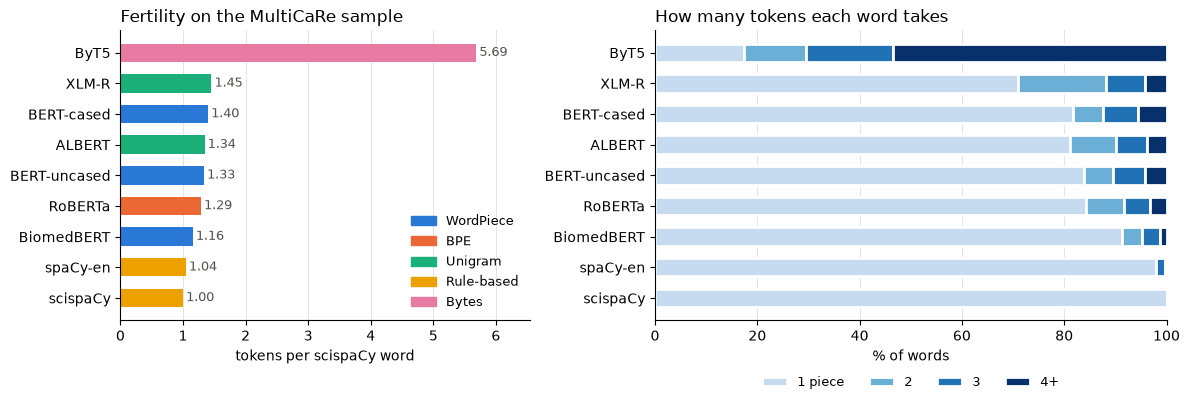

In [22]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.2), gridspec_kw={"width_ratios": [1, 1.25]})

# (a) fertility, colored by algorithm family
order = public["tokens / word"].astype(float).sort_values()
ax1.barh(order.index, order.values, height=0.6, color=[FAMILY_COLORS[TOKS[k].family] for k in order.index])
for y, v in enumerate(order.values):
    ax1.text(v + 0.05, y, f"{v:.2f}", va="center", fontsize=9, color="#52514e")
ax1.set_xlabel("tokens per scispaCy word"); ax1.set_title("Fertility on the MultiCaRe sample", loc="left")
ax1.grid(axis="y", visible=False); ax1.set_xlim(0, order.max() * 1.15)
handles = [plt.Rectangle((0, 0), 1, 1, color=c) for c in FAMILY_COLORS.values()]
ax1.legend(handles, FAMILY_COLORS.keys(), frameon=False, loc="lower right", fontsize=9)

# (b) how many pieces a word takes (ordered categories → one sequential hue, light to dark)
dist = pd.DataFrame({k: summary.loc[k, "_pieces_per_word"] for k in order.index}).T.fillna(0)
dist = dist.reindex(columns=[1, 2, 3, 4], fill_value=0)
dist = 100 * dist.div(dist.sum(axis=1), axis=0)
shades = ["#c6dbef", "#6baed6", "#2171b5", "#08306b"]
left = np.zeros(len(dist))
for col, shade, label in zip(dist.columns, shades, ["1 piece", "2", "3", "4+"]):
    ax2.barh(dist.index, dist[col], left=left, height=0.6, color=shade, label=label,
             edgecolor="white", linewidth=2)
    left += dist[col].values
ax2.set_xlabel("% of words"); ax2.set_xlim(0, 100); ax2.grid(axis="y", visible=False)
ax2.set_title("How many tokens each word takes", loc="left")
ax2.legend(ncol=4, frameon=False, loc="upper center", bbox_to_anchor=(0.5, -0.15), fontsize=9)
plt.tight_layout()

In [23]:
for key in TOKS:
    ex = summary.loc[key, "_unk_examples"]
    if ex:
        print(f"{key:13s} [UNK] for:", dict(ex.most_common(8)))

ALBERT        [UNK] for: {'<': 12, '>': 5, '~': 1, '|': 1}


Reading the table:

* **Fertility and sequence length go together.** Each extra piece per word
  is one more position of the 512-token budget. Even counted in *words*,
  half of the cases exceed 512; with the general BERT vocabulary about three
  quarters do, with BiomedBERT about 60%. Bytes multiply the length by ≈4.
* **A domain vocabulary is domain-specific.** BiomedBERT has the lowest
  fertility overall, yet the *longest* single case — the sample's one
  non-clinical text (an essay about the Theranos company), where its PubMed
  vocabulary does worse than BERT's general one.
* **Round-trip.** Rule-based, byte-level BPE and byte tokenizers are
  lossless. BERT-style and ALBERT tokenizers are *lossy* by design (case,
  accents, spaces around punctuation are gone); XLM-R keeps case but its
  SentencePiece normalization turns every newline into a space, so only the
  single-paragraph cases come back exactly. None of this matters for NER as
  long as the **offset mapping** points back to the original characters.
* **[UNK]** only appeared with ALBERT, whose vocabulary has no `<`, `>`, `~`
  or `|` (think `<0.5 mg/dl`). WordPiece would turn a *whole word* into
  `[UNK]` for a single missing character, but its 30k vocabularies cover
  every character of this sample. Byte-level BPE and bytes can never
  produce `[UNK]`.
* **Crossing tokens** come from tokenizers that do not split on punctuation
  first: byte-level BPE (`%.`, `);`) and SentencePiece (`▁(6`) merge
  characters of two words into one token — and possibly of two entities.

## 8. The NER view: do token boundaries respect entity boundaries?

A token tagger gives **one label per token**. If a gold entity starts or ends
*inside* a token, no labeling of the tokens can represent it exactly. We
check this on [MACCROBAT2018](https://doi.org/10.6084/m9.figshare.9764942.v2)
(200 case reports with character-level entity annotations — the data
`d4data/biomedical-ner-all` was fine-tuned on, loaded with the same helper as
`ner_pipeline.ipynb`):

> an entity is **aligned** with a tokenizer if its first character is the
> start of some token and its last character is the end of some token.

In [24]:
folder = ner_helpers.download_maccrobat()
mac_docs = [ner_helpers.read_brat(p) for p in sorted(Path(folder).glob("*.txt"))]
n_spans = sum(len(spans) for _, spans in mac_docs)
print(len(mac_docs), "reports,", n_spans, "entity mentions,",
      sum(len(t) for t, _ in mac_docs), "characters")

def entity_alignment(tok):
    aligned, misaligned = 0, Counter()
    for text, spans in mac_docs:
        toks = tok.tokenize(text)
        starts = {s for _, s, e in toks if e > s}
        ends = {e for _, s, e in toks if e > s}
        for sp in spans:
            if sp.start in starts and sp.end in ends:
                aligned += 1
            else:
                # show the entity in context: [entity] plus the characters around it
                misaligned[text[max(0, sp.start - 8):sp.start] + "[" + sp.text + "]" + text[sp.end:sp.end + 8]] += 1
    return aligned, misaligned

ALIGN = {key: entity_alignment(tok) for key, tok in TOKS.items()}
pd.DataFrame([{"tokenizer": k, "family": TOKS[k].family, "aligned entities (%)": round(100 * a / n_spans, 2),
               "misaligned": n_spans - a} for k, (a, _) in ALIGN.items()]).set_index("tokenizer")

200 reports, 24986 entity mentions, 565716 characters


,family,aligned entities (%),misaligned
tokenizer,,,
spaCy-en,Rule-based,99.28,181
scispaCy,Rule-based,99.04,240
BERT-uncased,WordPiece,99.91,22
BERT-cased,WordPiece,99.91,23
BiomedBERT,WordPiece,99.90,25
RoBERTa,BPE,99.37,157
ALBERT,Unigram,99.91,23
XLM-R,Unigram,98.38,406
ByT5,Bytes,100.00,0


In [25]:
for key in ["scispaCy", "spaCy-en", "RoBERTa", "XLM-R", "BERT-uncased"]:
    examples = [s.replace("\n", " ") for s, _ in ALIGN[key][1].most_common(6)]
    print(f"── {key}:"); print("   " + "\n   ".join(examples))

── scispaCy:
   ed from [Friedreich's ataxia].1 2 His
   ism was [catalase]-negativ
   atalase-[negative], bile e
   gative, [bile esculin]-negativ
   esculin-[negative], and py
   ve, and [pyrrolidonyl aminopeptidase]-negativ
── spaCy-en:
   ed from [Friedreich's ataxia].1 2 His
    with a [pressure ≤ 20 cm H2O]. No adj
   d BE of [−5.1 mmol/l]. C-reac
    798 to [98 μmol/l]. His EF
   vel was [1185.3 ng/mL]. Ultras
   e; and l[ong-term corticosteroid therapy complicated by adrenal insufficiency, type 2 diabetes mellitus and osteoporosis]. Recent
── RoBERTa:
   (EF) of [20%–25%]. The le
   educed ([15%]). Becau
   h EF of [20%]. In Mar
   aphy to [30%–35%]. 
   osis of [greater than 50%]. The po
   ased to [90%]. The ch
── XLM-R:
   ablets ([23.75 mg daily], p.o.),
   curium ([0.15 μg/kg]). Trans
    blade ([No.3]) and a 
   nes. In [June 2003], this m
   ce), as [S. suis serotype 2]. The pa
   rome in [1995]. Labora
── BERT-uncased:
   e; and l[ong-term corticosteroid therapy complic

All tokenizers align with more than 98% of the entities, but the
misalignments differ by a factor of 20, and each kind has a cause you can
read in the examples:

* **scispaCy** keeps hyphenated compounds whole (`catalase-negative`), while
  the annotators marked `catalase` and `negative` as two entities. Also
  footnote markers glued to a word (`ataxia.1`).
* **spaCy-en** splits hyphens, but leaves a sentence-final period attached
  to short units, as if they were abbreviations (`mmol/l.` → `l.`,
  `ng/mL.` → `mL.`, `H2O.`), so an entity like `98 μmol/l` ends inside a
  token.
* **RoBERTa** and **XLM-R** merge punctuation with the next characters
  (`%.`, `▁(23`), the *crossing tokens* of section 7.
* **BERT-style** tokenizers (and ALBERT) split on every punctuation mark
  first, so their few misalignments are **annotation errors**: a gold
  span that starts or ends in the middle of a word (`l[ong-term ...`,
  `[Histopathological examinatio]n`).
* **Bytes** align with everything — a boundary can fall between any two
  characters.

What happens then in `ner_pipeline.ipynb`? Its step ⑦ converts predicted
character spans into spaCy entities with
`doc.char_span(start, end, alignment_mode="expand")`, which silently
**widens** a misaligned span to whole tokens:

In [26]:
d = nlp.make_doc("She underwent EUS-FNA of the lesion.")
start = d.text.index("FNA"); end = start + 3
print("strict :", d.char_span(start, end))
print("expand :", d.char_span(start, end, alignment_mode="expand"))
print("contract:", d.char_span(start, end, alignment_mode="contract"))

strict : None
expand : EUS-FNA
contract: None


Splitting on punctuation before anything else, as BERT does, is one
reason the BERT family is a comfortable default for token classification:
the units it labels are never coarser than the units annotators mark.

## 9. A controlled experiment: same corpus, same size, three algorithms

The pretrained tokenizers above differ in *everything* at once: algorithm,
training corpus, vocabulary size, casing. To isolate the **algorithm**, we
train BPE, WordPiece and Unigram ourselves with the Hugging Face
`tokenizers` library:

* the **same training corpus** — the 200 MACCROBAT reports (≈566k characters),
* the **same normalizer** (BERT's: lower-case, strip accents) and the **same
  pre-tokenizer** (BERT's: whitespace + punctuation),
* the **same target vocabulary sizes**,

and evaluate on a **different** corpus of the same genre — our MultiCaRe
sample — so we measure generalization, not memorization.

In [27]:
from tokenizers import Tokenizer, models, normalizers, pre_tokenizers, trainers

def train_tokenizer(algorithm, vocab_size, corpus):
    if algorithm == "BPE":
        tok = Tokenizer(models.BPE(unk_token="[UNK]"))
        trainer = trainers.BpeTrainer(vocab_size=vocab_size, special_tokens=["[UNK]"], show_progress=False)
    elif algorithm == "WordPiece":
        tok = Tokenizer(models.WordPiece(unk_token="[UNK]"))
        trainer = trainers.WordPieceTrainer(vocab_size=vocab_size, special_tokens=["[UNK]"], show_progress=False)
    elif algorithm == "Unigram":
        tok = Tokenizer(models.Unigram())
        trainer = trainers.UnigramTrainer(vocab_size=vocab_size, special_tokens=["[UNK]"], unk_token="[UNK]",
                                          show_progress=False)
    tok.normalizer = normalizers.BertNormalizer(lowercase=True)
    tok.pre_tokenizer = pre_tokenizers.BertPreTokenizer()
    tok.train_from_iterator(corpus, trainer)
    return tok

def trained_tok(algorithm, tok):
    def tokenize(text):
        enc = tok.encode(text)
        return [(p, s, e) for p, (s, e) in zip(enc.tokens, enc.offsets)]
    return Tok(f"{algorithm}-{tok.get_vocab_size()}", algorithm, "MACCROBAT", "trained here",
               tokenize, lambda t: tok.decode(tok.encode(t).ids), tok.get_vocab_size(), 0, "[UNK]")

ALGORITHMS = ["WordPiece", "BPE", "Unigram"]
VOCAB_SIZES = [500, 1000, 2000, 4000, 8000]
train_corpus = [text for text, _ in mac_docs]

trained, rows = {}, []
for algorithm in ALGORITHMS:
    for size in VOCAB_SIZES:
        tok = train_tokenizer(algorithm, size, train_corpus)
        trained[algorithm, size] = tok
        st = corpus_stats(trained_tok(algorithm, tok), texts)
        rows.append({"algorithm": algorithm, "requested size": size, "actual size": tok.get_vocab_size(),
                     "tokens / word": st["tokens / word"], "words kept whole (%)": st["words kept whole (%)"],
                     "[UNK] tokens": st["[UNK] tokens"]})
controlled = pd.DataFrame(rows)
controlled.pivot(index="requested size", columns="algorithm",
                 values=["actual size", "tokens / word", "words kept whole (%)", "[UNK] tokens"]).round(2)

actual size                   tokens / word                   words kept whole (%)                   [UNK] tokens                  
algorithm              BPE Unigram WordPiece           BPE Unigram WordPiece                  BPE Unigram WordPiece          BPE Unigram WordPiece
requested size                                                                                                                                    
500                  500.0   500.0     500.0          2.22    2.28      2.40                51.69   51.06     48.80          7.0     0.0       7.0
1000                1000.0  1000.0    1000.0          1.87    1.95      1.99                60.53   55.89     57.64          7.0     0.0       7.0
2000                2000.0  2000.0    2000.0          1.58    1.72      1.67                70.31   59.57     67.85          7.0     0.0       7.0
4000                4000.0  4000.0    4000.0          1.38    1.59      1.43                79.27   61.48     77.87          7.0     0.0       7.0
8000                8000.0  5347.0    8000.0          1.25    1.57      1.28                85.95   61.62     84.93          7.0     0.0       7.0

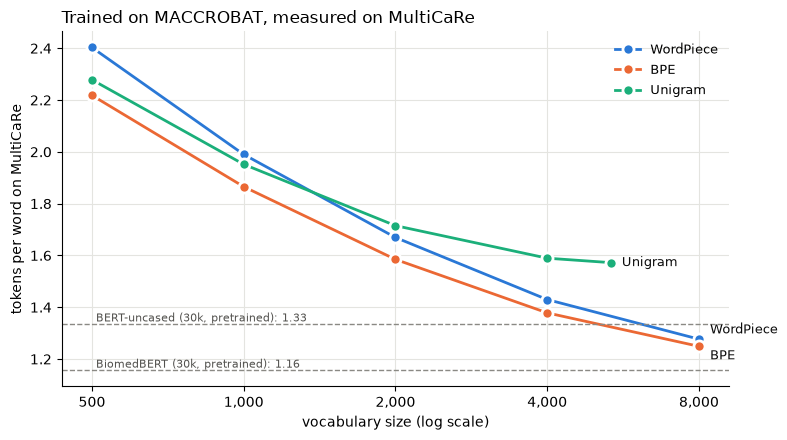

In [28]:
fig, ax = plt.subplots(figsize=(8, 4.5))
for algorithm in ALGORITHMS:
    d = controlled[controlled.algorithm == algorithm]
    ax.plot(d["actual size"], d["tokens / word"], marker="o", markersize=8, linewidth=2,
            color=FAMILY_COLORS[algorithm], markeredgecolor="white", markeredgewidth=2)
    last = d.iloc[-1]
    dy = {"WordPiece": 7, "BPE": -7, "Unigram": 0}[algorithm]   # keep the two close end labels apart
    ax.annotate(algorithm, (last["actual size"], last["tokens / word"]), xytext=(8, dy),
                textcoords="offset points", va="center", fontsize=9, color="#0b0b0b")

# references: the two 30k pretrained WordPiece vocabularies use the same normalizer + pre-tokenizer
for key in ["BERT-uncased", "BiomedBERT"]:
    v = public.loc[key, "tokens / word"]
    ax.axhline(v, color="#8a8984", linestyle="--", linewidth=1)
    ax.text(VOCAB_SIZES[0], v, f" {key} (30k, pretrained): {v:.2f}", va="bottom", fontsize=8, color="#52514e")

ax.set_xscale("log", base=2)
ax.set_xticks(VOCAB_SIZES, [f"{v:,}" for v in VOCAB_SIZES])
ax.set_xlabel("vocabulary size (log scale)"); ax.set_ylabel("tokens per word on MultiCaRe")
ax.set_title("Trained on MACCROBAT, measured on MultiCaRe", loc="left")
ax.legend(ALGORITHMS, frameon=False, loc="upper right", fontsize=9)
plt.tight_layout()

In [29]:
SIZE = 4000
pd.DataFrame({alg: {w: " ".join(trained[alg, SIZE].encode(w).tokens) for w in CLINICAL_WORDS}
              for alg in ALGORITHMS})

,WordPiece,BPE,Unigram
fever,fever,fever,fever
pain,pain,pain,pain
nausea,nausea,nausea,n ause a
constipation,cons ##ti ##pa ##tion,con st ip ation,consti pation
dyspnea,dyspnea,dyspnea,dyspn e a
hypokalemia,hypok ##ale ##m ##ia,hypo k al emia,hypokal emia
tachycardia,tachycardia,tachycardia,tachycardi a
pancreatitis,pancreatitis,pancreatitis,pancreat itis
pneumothorax,pneum ##othorax,pneum o thorax,pneumo thora x
adenocarcinoma,adenocarcinoma,adenocarcinoma,adeno carcinoma


What the controlled experiment shows:

* **With everything else equal, BPE and WordPiece are close**, BPE
  slightly ahead at every size. That is expected here: Hugging Face's
  `WordPieceTrainer` *learns its vocabulary with BPE merges*; what differs is
  the segmentation rule (greedy longest-match instead of replaying merges)
  and the `##` prefix, which makes WordPiece store word-initial and
  word-internal versions of a string as separate entries (`ia` and `##ia`),
  so the same budget holds fewer distinct strings. (Google's
  likelihood-based WordPiece trainer was never released.)
* **Unigram** needs more tokens per word and keeps far fewer words whole.
  Its splits often fall on morpheme boundaries (`adeno carcinoma`,
  `pancreat itis`, `hepato splen omegal y`) but leave odd single letters
  (`dyspn e a`), and on this small corpus the trainer stops at ~5,300
  pieces however many are requested. In exchange it never produced
  `[UNK]` here, while BPE and WordPiece met 7 characters never seen in
  MACCROBAT.
* **A small in-domain vocabulary can beat a large general one.** 8,000
  pieces learned from only 200 case reports (≈0.5 MB of text) already give
  fewer tokens per word on *other* case reports than BERT's 30,000
  general-English pieces; BiomedBERT's 30,000 PubMed pieces are better
  still — the lesson of section 6 again.

## 10. Summary

| | Rule-based (spaCy) | BPE | WordPiece | Unigram (SentencePiece) | Bytes |
|---|---|---|---|---|---|
| unit | words, punctuation | learned sub-words | learned sub-words | learned sub-words | UTF-8 bytes |
| vocabulary built by | hand-written rules | merging frequent pairs | merging pairs by likelihood | pruning a large candidate set | — |
| segmentation | rules | replay merges | greedy longest match | most probable (Viterbi) | — |
| unknown input | n/a (no vocabulary) | never (byte-level) | a missing character makes the whole word `[UNK]` | `<unk>` per missing character (ALBERT: `<`, `>`, `≥`) | never |
| space handling | `whitespace_` attribute | `Ġ` inside token | dropped (pre-tokenizer) | `▁` inside token | space byte |
| lossless | yes | yes (byte-level) | no (spaces around punctuation; uncased: case, accents) | no (whitespace normalized; uncased: case) | yes |
| typical models | spaCy pipelines | GPT-2/4, RoBERTa, ModernBERT, Llama | BERT, DistilBERT, BiomedBERT | ALBERT, T5, XLM-R | ByT5, CANINE |

**For the NER pipeline:**

1. **The tokenizer comes with the model.** A pretrained Transformer's
   embedding table has one row per vocabulary entry: we cannot pair
   `d4data/biomedical-ner-all` with another tokenizer. Choosing a model *is*
   choosing a tokenizer — so the comparisons above are really part of
   choosing a model.
2. **Offsets are the glue.** spaCy tokens, sub-word tokens and gold
   annotations are reconciled through character offsets
   (`return_offsets_mapping`, `word_ids()`, `token.idx`). Lossy normalization
   is harmless as long as offsets are kept.
3. **Domain vocabulary pays twice:** fewer pieces per clinical word (each
   piece more meaningful, shorter sequences) and fewer cases over the 512
   limit. A BiomedBERT-based NER model is a natural candidate for a later
   notebook.
4. **Case matters in clinical text** (`US`/`us`, `CT`, gene names); the
   uncased model used in `ner_pipeline.ipynb` discards it.
5. **Boundaries:** BERT-style pre-tokenization (split on all punctuation)
   aligns with 99.9% of the gold entity boundaries; scispaCy's coarser
   tokens miss ten times more, and the pipeline's last step
   (`alignment_mode="expand"`) silently widens those entities.

Next: `ner_pipeline.ipynb`, step ③ onwards, follows the WordPiece ids into
BERT's embedding table.

## 🧩 Challenges

**🧩 Challenge 1 — predict, then check.** Add
`"Bio_ClinicalBERT": ("WordPiece", "emilyalsentzer/Bio_ClinicalBERT", "...")`
to `TOKENIZERS` and re-run from section 5. *Before running*, write down how
you expect it to split `hypokalemia` and `US`. (Hint: which vocabulary did it
inherit from BioBERT?)

In [30]:
# your prediction:
# your code:

**🧩 Challenge 2 — fix a misalignment.** Pick the most frequent scispaCy
misalignment in section 8 and change the tokenizer rules so that it
disappears (e.g. add an infix with `nlp.tokenizer.infix_finditer`, see
`spacy.util.compile_infix_regex`). Re-run `entity_alignment`. Did the
alignment rate improve? Which strings in section 2's table changed — for
better or worse?

In [31]:
# your code:

**🧩 Challenge 3 — when does a word become a token?** Using
`train_tokenizer`, find for each algorithm the smallest vocabulary size at
which `pneumothorax` is kept as a single piece. Then train a **cased**
WordPiece (`BertNormalizer(lowercase=False)`) of size 4000: what happens to
the tokens per word, and why?

In [32]:
# your code:

---
**Credits.** MultiCaRe — Nievas Offidani et al.,
[Zenodo 10.5281/zenodo.10079369](https://doi.org/10.5281/zenodo.10079369).
MACCROBAT2018 — Caufield (2019),
[figshare 10.6084/m9.figshare.9764942.v2](https://doi.org/10.6084/m9.figshare.9764942.v2), CC BY 4.0.
Tokenizers from the Hugging Face Hub (see each model card for its license).
References: Sennrich et al. 2016 (BPE); Schuster & Nakajima 2012, Devlin et al. 2019 (WordPiece);
Kudo 2018, Kudo & Richardson 2018 (Unigram, SentencePiece); Xue et al. 2022 (ByT5);
Gu et al. 2021 (BiomedBERT/PubMedBERT).